# SHORT Bollinger + RSI + lọc biến động thấp — grid, kiểm tra ngoài mẫu, walk-forward

Notebook dùng `vol_filter_engine.py` cùng thư mục (numba CPU, không cần GPU). Sửa **ô Cấu hình**, rồi **Run All**.

**Vào lệnh short ở close nến `t`:** `close[t-1] > lower[t] > close[t]` (đóng cửa phá xuống dải dưới Bollinger) **và** `RSI[t] < rsi_threshold` **và** (nếu bật lọc) `vol_ratio[t] < vol_ratio_max`.

**Lọc biến động thấp:** `vol_ratio = độ lệch chuẩn log-return của vol_window nến gần nhất / trung vị của nó trong vol_days ngày trước`. `vol_ratio < 1` nghĩa là thị trường đang yên hơn bình thường → cú phá dải xuất phát từ vùng tích lũy. `vol_ratio_max = 0` tắt lọc (khi đó lệnh trùng hệt `multi_position_engine.cpu_trace`).

**Rủi ro và thoát lệnh:** risk = `sl_multiplier × (upper − entry)`; stop = entry + risk; TP = entry − `tp_sl_ratio` × risk (`0` = không TP); timeout `max_holding_bars` nến. **Trailing** (`trail_r`, 0 = tắt): sau mỗi nến, stop kéo xuống `đáy thấp nhất từ lúc vào lệnh + trail_r × risk` nếu thấp hơn stop hiện tại (không bao giờ nới ra, có hiệu lực từ nến sau); lệnh đóng ở stop đã kéo ghi `(entry − stop) / risk` R, outcome `trailing_stop`.

**Bỏ RSI:** `rsi_threshold = 100` (short) bỏ điều kiện RSI — nến phá dải luôn đóng cửa giảm nên RSI < 100. Khi đó `rsi_window` không còn tác dụng: chỉ để một giá trị `rsi_window` cho các hàng 100, nếu không grid có hàng trùng. Phí vào `0.001 / sl_ratio` (bỏ lệnh nếu > 0.2R), phí giữ mỗi 8 giờ; một lệnh mỗi lúc.

**Kết quả nghiên cứu (36 coin, 15min, 24–25/10/2026):**
- Lọc biến động thấp (ngưỡng 1.0) nâng bộ tham số điển hình từ ~1.9 lên ~5–6.7 R/năm/coin trên 2022–2025, 92–97% coin có lãi; có tác dụng với cả 7 logic vào lệnh khác đã thử (Keltner, MACD, Supertrend, DMI, Donchian, pullback ADX).
- TP xa tốt hơn: 3R ≥ 2.5R > 2R > 1.5R > 1.1R. Thoát bằng chỉ báo (dải giữa, RSI 50, EMA50), trailing theo ATR (quá chặt, ~0.3–0.5R), SL theo đỉnh N nến, phía long: không giúp.
- **Trailing theo R, không TP** (26/10/2026, lọc biến động bật): `trail_r = 1` giữ R/năm ≈ TP 3R (5.6 vs 5.9) nhưng maxDD 8.7 vs 13.2; `trail_r = 1.5` R/năm 7.2, maxDD 10.9; 2026: +1.2 / +1.0 vs +0.6 R/coin. Thêm TP vào trailing làm kém đi; `trail_r` < 1 quá chặt.
- Walk-forward 24/12 (top-10 theo perf/maxDD), 2024-01 → 2026-10: +14.3 R/coin, maxDD 3.0 (gốc không lọc: +4.7, maxDD 3.6). Chỉ 2026 là ngoài mẫu sạch: +1.0 so với −1.3 R/coin.
- Coin hợp: alt beta cao (CHZ, ALGO, SAND, GALA, AVAX, ATOM, XRP, FIL, MANA, AXS…); coin không hợp: LTC, CRV, BNB, PEOPLE, TRX.
- Chọn tham số trong grid gần như không dự báo được ngoài mẫu (top-10 chỉ hơn ngẫu nhiên ~0.5 R/coin/năm với train 4 năm) → xem **trung vị cả grid** (ô "Theo từng chiều") hơn là bộ đứng đầu.

**Ngày:** `TRAIN_START` → trước `TEST_START` là train, `TEST_START` → `TEST_END` là test. Nên đặt `TRAIN_START`, `TEST_START` vào ngày 1 của tháng (R theo tháng dùng cho walk-forward). Dữ liệu được nạp từ sớm hơn `WARMUP_DAYS` để chỉ báo đã "ấm" khi train bắt đầu.

In [101]:
# CẤU HÌNH — sửa ô này trước khi chạy
DATA_CSV = "../data_5m/avaxusdt_futures_5min.csv"
TIMEFRAME = "5min"            # "15min", "1h", ... (max_holding_bars và vol_window tính theo nến)
TRAIN_START = "2024-01-01"
TEST_START = "2025-07-01"      # train = [TRAIN_START, TEST_START), test = [TEST_START, TEST_END]
TEST_END = "2026-10-19"
WARMUP_DAYS = 120              # nạp thêm dữ liệu trước TRAIN_START để chỉ báo ấm
SIDE = -1                      # -1 short (đã nghiên cứu), +1 long (RSI > rsi_threshold, dải trên)

SCORE = "perf/maxDD"           # "perf/maxDD" (khuyên dùng), "sharpe" (theo tháng), "perf"
#SCORE = "sharpe"
TOP_K = 10                     # số bộ đứng đầu dùng cho kiểm tra ngoài mẫu / walk-forward
MIN_TRADES = 100               # số lệnh tối thiểu trong train
MIN_TRADES_PER_YEAR = 20       # số lệnh của năm ít lệnh nhất (quy ra cả năm)

# Grid: số bộ = tích độ dài các danh sách
SEARCH_SPACE = {
    # "boll_window": [50, 100, 200],
    # "boll_window_dev": [2.0, 2.5],
    # "rsi_window": [5, 14],
    # "rsi_threshold": [15, 25, 35],
    # "sl_multiplier": [0.6, 0.9, 1.2],
    #"sl_multiplier": [0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5],
    "boll_window": [60, 80, 100, 200, 300, 400, 500, 600, 700],
    "boll_window_dev": [1.8, 2.0, 2.2, 2.5],
    "rsi_window": [5, 7, 9, 14, 20, 30],
    "rsi_threshold": [5, 10, 15, 20, 25, 30, 35, 40],
    "sl_multiplier": [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0],
    "tp_sl_ratio": [1.1],      # 0 = không chốt lời
    "max_holding_bars": [192, 384],
    "vol_window": [96],                       # nến (96 = 1 ngày ở 15min)
    "vol_days": [30],                         # ngày
    "vol_ratio_max": [0, 1.0],                # 0 = tắt lọc; giữ cả 0 để so sánh
    "trail_r": [0],                           # trailing stop theo R, 0 = tắt; nên thử [0, 1.0, 1.5] với tp_sl_ratio [0, 3.0]
}
# rsi_threshold = 100 bỏ điều kiện RSI (short); khi đó chỉ để một giá trị rsi_window cho các hàng này

# Walk-forward theo tháng: train WF_TRAIN tháng, giao dịch WF_TEST tháng tiếp theo, lặp lại
WF_TRAIN = 24
WF_TEST = 12
WF_FIRST_TEST = "2024-01-01"

# Nhiều coin (ô cuối, tùy chọn): để [] để bỏ qua
COINS = []   # ví dụ ["avax", "chz", "algo", "sand", "gala", "atom", "btc", "eth", "bnb", "ltc"]

In [102]:
# Nạp vol_filter_engine.py cùng thư mục (cũng chạy được khi kernel bắt đầu ở thư mục khác trong repo)
from pathlib import Path
import importlib.util
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
FOLDER = "short_bollinger+RSI+volfilter"
candidates = []
for parent in (Path.cwd(), *Path.cwd().parents):
    if parent.name == FOLDER:
        candidates.append(parent / "vol_filter_engine.py")
    candidates.append(parent / "reference" / FOLDER / "vol_filter_engine.py")
engine_path = next((p.resolve() for p in candidates if p.is_file()), None)
if engine_path is None:
    raise FileNotFoundError("Không tìm thấy vol_filter_engine.py")
# bỏ bản đã cache để chạy lại ô này là nạp bản mới nhất
for name in ("vol_filter_engine", "multi_position_engine"):
    sys.modules.pop(name, None)
spec = importlib.util.spec_from_file_location("vol_filter_engine", engine_path)
vfe = importlib.util.module_from_spec(spec)
sys.modules["vol_filter_engine"] = vfe
spec.loader.exec_module(vfe)
csv_path = (engine_path.parent / DATA_CSV).resolve() if not Path(DATA_CSV).is_absolute() else Path(DATA_CSV)
if not csv_path.is_file():
    csv_path = Path(DATA_CSV).expanduser().resolve()
if not csv_path.is_file():
    raise FileNotFoundError(csv_path)
print("Engine:", engine_path)
print("CSV:", csv_path)

Engine: C:\Users\Legion\Desktop\TradingProject\reference\short_bollinger+RSI+volfilter\vol_filter_engine.py
CSV: C:\Users\Legion\Desktop\TradingProject\reference\data_5m\avaxusdt_futures_5min.csv


In [103]:
# Đọc dữ liệu, tạo grid, chạy (R theo tháng cho toàn bộ giai đoạn + thống kê theo lệnh trên train)
load_start = (pd.Timestamp(TRAIN_START) - pd.Timedelta(days=WARMUP_DAYS)).strftime("%Y-%m-%d")
bars = vfe.load_bars(csv_path, TIMEFRAME, load_start, TEST_END)
for name in ("TRAIN_START", "TEST_START"):
    if pd.Timestamp(globals()[name]).day != 1:
        print(f"Lưu ý: {name} không phải ngày 1 — bảng theo tháng/năm sẽ lệch một phần tháng")
months = vfe.month_index(bars, pd.Timestamp(TRAIN_START).strftime("%Y-%m"))
month_start = pd.date_range(pd.Timestamp(TRAIN_START).to_period("M").to_timestamp(), periods=months.max() + 1, freq="MS")
train_from = int(np.searchsorted(bars.timestamp.to_numpy(), np.datetime64(pd.Timestamp(TRAIN_START))))
test_from = int(np.searchsorted(bars.timestamp.to_numpy(), np.datetime64(pd.Timestamp(TEST_START))))
n_train_m = int((pd.Timestamp(TEST_START).to_period("M") - pd.Timestamp(TRAIN_START).to_period("M")).n)
grid = vfe.parameter_grid(SEARCH_SPACE)
print(f"Dữ liệu: {len(bars):,} nến; {bars.timestamp.iloc[0]} → {bars.timestamp.iloc[-1]}")
print(f"Train: {bars.timestamp.iloc[train_from]} → {bars.timestamp.iloc[test_from - 1]} ({n_train_m} tháng); "
      f"test: {bars.timestamp.iloc[test_from] if test_from < len(bars) else '—'} → {bars.timestamp.iloc[-1]}")
print(f"Grid: {len(grid):,} bộ tham số")

import time
t0 = time.perf_counter()
R, N, stats = vfe.run_grid(SIDE, bars, grid, TIMEFRAME, months, stats_from=train_from, stats_to=test_from)
print(f"Thời gian: {time.perf_counter() - t0:.1f}s (lần đầu có thêm thời gian biên dịch numba)")

Dữ liệu: 329,184 nến; 2023-09-03 00:00:00 → 2026-10-19 23:55:00
Train: 2024-01-01 00:00:00 → 2025-06-30 23:55:00 (18 tháng); test: 2025-07-01 00:00:00 → 2026-10-19 23:55:00
Grid: 110,592 bộ tham số
Thời gian: 56.3s (lần đầu có thêm thời gian biên dịch numba)


In [104]:
# TÍNH SCORE TRÊN TRAIN — chạy lại riêng ô này sau khi đổi SCORE, MIN_TRADES*, TOP_K
train_years = n_train_m / 12
Rm_train, Nm_train = R[:, :n_train_m], N[:, :n_train_m]
result = grid.copy()
result["train_R"] = stats.performance
result["train_maxDD"] = stats.max_dd
result["train_trades"] = stats.number_of_trade
result["train_win_rate"] = stats.win_rate
result["train_R_per_year"] = result.train_R / train_years
# năm lịch trong train (bỏ năm < 6 tháng nếu còn năm khác), lệnh của năm ít lệnh nhất quy ra cả năm
years = month_start[:n_train_m].year
year_spans = [(np.flatnonzero(years == y)[0], np.flatnonzero(years == y)[-1] + 1) for y in sorted(set(years))]
long_spans = [s for s in year_spans if s[1] - s[0] >= 6] or year_spans
result["min_trades_per_year"] = np.min([Nm_train[:, a:b].sum(1) * 12 / (b - a) for a, b in long_spans], axis=0)
for y, (a, b) in zip(sorted(set(years)), year_spans):
    result[f"R_{y}"] = Rm_train[:, a:b].sum(1)
result["test_R"] = R[:, n_train_m:].sum(1)
result["test_trades"] = N[:, n_train_m:].sum(1)
sd = Rm_train.std(1, ddof=1)
score = {"perf/maxDD": result.train_R / np.maximum(result.train_maxDD, 1.0),
         "perf": result.train_R,
         "sharpe": pd.Series(np.where(sd > 0, Rm_train.mean(1) / np.where(sd > 0, sd, 1), np.nan))}[SCORE]
eligible = (result.train_trades >= MIN_TRADES) & (result.min_trades_per_year >= MIN_TRADES_PER_YEAR)
result["score"] = np.where(eligible, score, np.nan)
ranked = result[eligible].sort_values("score", ascending=False)
print(f"Score: {SCORE} | đủ điều kiện: {int(eligible.sum()):,}/{len(result):,} bộ "
      f"(≥ {MIN_TRADES} lệnh train, ≥ {MIN_TRADES_PER_YEAR} lệnh/năm)")
show = list(SEARCH_SPACE) + ["score", "train_R", "train_R_per_year", "train_maxDD", "train_trades", "train_win_rate",
                             "min_trades_per_year"] + [c for c in result if c.startswith("R_")] + ["test_R", "test_trades"]
display(ranked[show].head(50).round(3))

Score: perf/maxDD | đủ điều kiện: 48,267/110,592 bộ (≥ 100 lệnh train, ≥ 20 lệnh/năm)


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio,max_holding_bars,vol_window,vol_days,vol_ratio_max,...,train_R,train_R_per_year,train_maxDD,train_trades,train_win_rate,min_trades_per_year,R_2024,R_2025,test_R,test_trades
22735,80,2.5,9,20,0.8,1.1,384,96,30,1.0,...,60.327,40.218,3.358,166,0.675,94.0,42.561,17.766,-6.700,183
34449,100,2.5,7,15,0.9,1.1,192,96,30,1.0,...,43.370,28.913,2.554,130,0.700,70.0,33.045,10.325,4.005,141
34447,100,2.5,7,15,0.8,1.1,384,96,30,1.0,...,51.484,34.323,3.131,130,0.692,74.0,43.546,7.937,-0.668,137
21583,80,2.5,5,10,0.8,1.1,384,96,30,1.0,...,54.005,36.003,3.431,135,0.689,76.0,39.747,14.258,-1.700,159
34445,100,2.5,7,15,0.8,1.1,192,96,30,1.0,...,45.800,30.533,3.131,133,0.699,74.0,36.221,9.579,5.637,142
22739,80,2.5,9,20,0.9,1.1,384,96,30,1.0,...,48.173,32.115,3.310,162,0.654,92.0,37.401,10.771,-3.302,173
35599,100,2.5,14,25,0.8,1.1,384,96,30,1.0,...,45.456,30.304,3.228,126,0.667,62.0,36.065,9.390,-8.954,137
36751,100,2.5,30,35,0.8,1.1,384,96,30,1.0,...,46.526,31.017,3.321,156,0.641,90.0,32.251,14.275,-4.229,142
22733,80,2.5,9,20,0.8,1.1,192,96,30,1.0,...,50.629,33.753,3.621,173,0.659,98.0,31.695,18.934,4.504,192
21587,80,2.5,5,10,0.9,1.1,384,96,30,1.0,...,45.180,30.120,3.353,133,0.669,74.0,35.819,9.360,4.907,150


In [105]:
# Theo từng chiều tham số: TRUNG VỊ cả grid (đáng tin hơn bộ đứng đầu)
def family(frame):
    ok = frame[(frame.train_trades >= MIN_TRADES) & (frame.min_trades_per_year >= MIN_TRADES_PER_YEAR)]
    return pd.Series({
        "số bộ": len(frame), "% đủ điều kiện": len(ok) / len(frame),
        "lệnh train/năm": ok.train_trades.median() / train_years if len(ok) else np.nan,
        "train R/năm (trung vị)": ok.train_R_per_year.median() if len(ok) else np.nan,
        "% bộ train lãi": (ok.train_R > 0).mean() if len(ok) else np.nan,
        "train maxDD (trung vị)": ok.train_maxDD.median() if len(ok) else np.nan,
        "test R (trung vị)": ok.test_R.median() if len(ok) else np.nan,
        "% bộ test lãi": (ok.test_R > 0).mean() if len(ok) else np.nan,
    })


for col in ["vol_ratio_max", "tp_sl_ratio", "boll_window", "boll_window_dev", "rsi_window", "rsi_threshold",
            "sl_multiplier", "max_holding_bars", "vol_window", "vol_days", "trail_r"]:
    if result[col].nunique() > 1:
        print("Theo", col)
        cols = ["train_trades", "min_trades_per_year", "train_R_per_year", "train_R", "train_maxDD", "test_R"]
        display(result.groupby(col)[cols].apply(family).round(3))
if result.vol_ratio_max.nunique() > 1 and result.tp_sl_ratio.nunique() > 1:
    print("vol_ratio_max × tp_sl_ratio — train R/năm (trung vị bộ đủ điều kiện)")
    display(result[eligible].pivot_table(index="vol_ratio_max", columns="tp_sl_ratio", values="train_R_per_year",
                                         aggfunc="median").round(2))
if result.trail_r.nunique() > 1 and result.tp_sl_ratio.nunique() > 1:
    for value, label in (("train_R_per_year", "train R/năm"), ("train_maxDD", "train maxDD"), ("test_R", "test R")):
        print(f"trail_r × tp_sl_ratio — {label} (trung vị bộ đủ điều kiện)")
        display(result[eligible].pivot_table(index="trail_r", columns="tp_sl_ratio", values=value,
                                             aggfunc="median").round(2))

Theo vol_ratio_max


,số bộ,% đủ điều kiện,lệnh train/năm,train R/năm (trung vị),% bộ train lãi,train maxDD (trung vị),test R (trung vị),% bộ test lãi
vol_ratio_max,,,,,,,,
0.0,55296.0,0.522,154.667,4.699,0.813,8.335,1.054,0.554
1.0,55296.0,0.351,128.000,8.809,0.918,7.160,-3.510,0.352


Theo boll_window


,số bộ,% đủ điều kiện,lệnh train/năm,train R/năm (trung vị),% bộ train lãi,train maxDD (trung vị),test R (trung vị),% bộ test lãi
boll_window,,,,,,,,
60,12288.0,0.555,295.333,3.084,0.611,17.360,-12.231,0.183
80,12288.0,0.545,255.333,6.308,0.745,14.298,-8.159,0.223
100,12288.0,0.537,232.000,9.792,0.884,11.328,-4.247,0.320
200,12288.0,0.512,155.333,8.616,0.961,7.760,1.822,0.578
300,12288.0,0.488,123.333,4.769,0.888,7.090,-1.485,0.429
400,12288.0,0.405,109.333,5.890,0.906,5.540,3.160,0.690
500,12288.0,0.333,104.667,6.474,0.960,4.391,3.314,0.790
600,12288.0,0.290,97.333,5.486,0.961,4.138,1.774,0.726
700,12288.0,0.264,89.333,4.721,0.946,4.232,2.376,0.780


Theo boll_window_dev


,số bộ,% đủ điều kiện,lệnh train/năm,train R/năm (trung vị),% bộ train lãi,train maxDD (trung vị),test R (trung vị),% bộ test lãi
boll_window_dev,,,,,,,,
1.8,27648.0,0.462,151.333,5.172,0.796,8.401,-2.743,0.371
2.0,27648.0,0.453,144.667,5.508,0.821,8.013,-0.024,0.499
2.2,27648.0,0.427,146.667,6.594,0.875,8.063,-0.485,0.478
2.5,27648.0,0.404,136.667,7.328,0.942,7.117,1.079,0.556


... (4 outputs left out)

Theo sl_multiplier


,số bộ,% đủ điều kiện,lệnh train/năm,train R/năm (trung vị),% bộ train lãi,train maxDD (trung vị),test R (trung vị),% bộ test lãi
sl_multiplier,,,,,,,,
0.5,6912.0,0.459,174.667,2.801,0.623,14.123,-10.218,0.221
0.6,6912.0,0.453,165.333,4.709,0.738,12.414,-10.039,0.195
0.7,6912.0,0.445,160.667,5.482,0.753,12.234,-8.735,0.265
0.8,6912.0,0.441,156.000,6.853,0.828,10.430,-6.585,0.279
0.9,6912.0,0.438,152.000,8.246,0.888,8.996,-2.527,0.373
1.0,6912.0,0.436,148.667,8.884,0.917,8.170,-0.668,0.465
1.1,6912.0,0.435,146.000,8.803,0.919,7.644,-0.536,0.481
1.2,6912.0,0.434,144.000,7.558,0.908,7.159,0.301,0.515
1.3,6912.0,0.433,141.333,6.413,0.884,6.941,0.477,0.527


Theo max_holding_bars


,số bộ,% đủ điều kiện,lệnh train/năm,train R/năm (trung vị),% bộ train lãi,train maxDD (trung vị),test R (trung vị),% bộ test lãi
max_holding_bars,,,,,,,,
192,55296.0,0.449,155.333,5.894,0.862,7.261,0.961,0.546
384,55296.0,0.424,134.667,6.335,0.848,8.468,-2.214,0.396


In [106]:
# Ngoài mẫu: top-K theo score trên train, so với chọn ngẫu nhiên (trung vị bộ đủ điều kiện)
test_months = R.shape[1] - n_train_m
if test_months <= 0:
    print("Không có dữ liệu test")
else:
    rows = []
    groups = {"tất cả": eligible}
    if result.vol_ratio_max.nunique() > 1:
        groups.update({f"vol_ratio_max = {v:g}": eligible & (result.vol_ratio_max == v)
                       for v in sorted(result.vol_ratio_max.unique())})
    for label, mask in groups.items():
        sub = result[mask].sort_values("score", ascending=False)
        if sub.empty:
            continue
        top = sub.head(TOP_K)
        rows.append({"nhóm": label, "số bộ": len(sub), f"top-{TOP_K} train R/năm": top.train_R_per_year.mean(),
                     f"top-{TOP_K} test R": top.test_R.mean(), f"top-{TOP_K} % test lãi": (top.test_R > 0).mean(),
                     "top-1 test R": top.test_R.iloc[0], "ngẫu nhiên: test R trung vị": sub.test_R.median(),
                     "ngẫu nhiên: % test lãi": (sub.test_R > 0).mean()})
    print(f"Test {test_months} tháng ({TEST_START} → {TEST_END})")
    display(pd.DataFrame(rows).round(2))

Test 16 tháng (2025-07-01 → 2026-10-19)


,nhóm,số bộ,top-10 train R/năm,top-10 test R,top-10 % test lãi,top-1 test R,ngẫu nhiên: test R trung vị,ngẫu nhiên: % test lãi
0,tất cả,48267,32.73,-0.65,0.4,-6.70,-0.60,0.47
1,vol_ratio_max = 0,28859,16.87,5.39,0.9,3.38,1.05,0.55
2,vol_ratio_max = 1,19408,32.73,-0.65,0.4,-6.70,-3.51,0.35


In [107]:
# Walk-forward theo tháng: mỗi lần chọn top-K theo SCORE trên WF_TRAIN tháng trước, giao dịch WF_TEST tháng tiếp theo
# (score dùng max DD theo tháng — xấp xỉ, nhỏ hơn max DD theo lệnh)
first = int((pd.Timestamp(WF_FIRST_TEST).to_period("M") - pd.Timestamp(TRAIN_START).to_period("M")).n)
total_m = R.shape[1]
if first - WF_TRAIN < 0:
    print(f"WF_FIRST_TEST cần ≥ TRAIN_START + {WF_TRAIN} tháng")
else:
    def wf_series(mask):
        out = np.zeros(total_m - first)
        for m in range(first, total_m, WF_TEST):
            a, b, e = m - WF_TRAIN, m, min(m + WF_TEST, total_m)
            tr, n = R[:, a:b].sum(1), N[:, a:b].sum(1)
            ok = mask & (n >= MIN_TRADES * WF_TRAIN / max(n_train_m, 1))
            if ok.sum() == 0:
                continue
            x = R[:, a:b]
            sd = x.std(1, ddof=1)
            sc = {"perf/maxDD": tr / np.maximum(vfe.monthly_max_dd(x), 1.0), "perf": tr,
                  "sharpe": np.where(sd > 0, x.mean(1) / np.where(sd > 0, sd, 1), -np.inf)}[SCORE]
            sc = np.where(ok, sc, -np.inf)
            top = np.argsort(-sc)[:TOP_K]
            out[m - first:e - first] = R[top, m:e].mean(0)
        return out

    variants = {"tất cả": np.ones(len(grid), bool)}
    if result.vol_ratio_max.nunique() > 1:
        variants.update({f"vol_ratio_max = {v:g}": (result.vol_ratio_max == v).to_numpy()
                         for v in sorted(result.vol_ratio_max.unique())})
    curves, rows = {}, []
    for label, mask in variants.items():
        s = wf_series(mask)
        eq = np.cumsum(s)
        curves[label] = eq
        idx = pd.Index(month_start[first:])
        yearly = pd.Series(s, index=idx).groupby(idx.year).sum()
        rows.append({"biến thể": label, "R tổng": eq[-1],
                     "maxDD (tháng)": (np.maximum.accumulate(np.maximum(eq, 0)) - eq).max(),
                     "% tháng lãi": (s > 0).mean(), **{f"R {y}": v for y, v in yearly.items()}})
    display(pd.DataFrame(rows).round(2))
    ax = pd.DataFrame(curves, index=month_start[first:]).plot(figsize=(14, 4), drawstyle="steps-post")
    ax.set(title=f"Walk-forward {WF_TRAIN}/{WF_TEST} tháng, top-{TOP_K} theo {SCORE} (R lũy kế)", ylabel="R")
    plt.show()

WF_FIRST_TEST cần ≥ TRAIN_START + 24 tháng


Tham số: {'boll_window': 80.0, 'boll_window_dev': 2.5, 'rsi_window': 9.0, 'rsi_threshold': 20.0, 'sl_multiplier': 0.8, 'tp_sl_ratio': 1.1, 'max_holding_bars': 384.0, 'vol_window': 96.0, 'vol_days': 30.0, 'vol_ratio_max': 1.0, 'trail_r': 0.0} | ID trong grid: 22735
Đối chiếu với grid: lệch tối đa theo tháng 0.00e+00


lệnh       R  R_mỗi_lệnh  tỷ_lệ_thắng
năm  phần                                        
2024 train   119  42.561       0.358        0.681
2025 test     70  -4.612      -0.066        0.486
     train    47  17.766       0.378        0.660
2026 test    113  -2.087      -0.018        0.504

size   mean      sum
phần  outcome                          
test  stop           89 -1.069  -95.101
      take_profit    87  1.022   88.893
      timeout         7 -0.070   -0.492
train stop           51 -1.053  -53.726
      take_profit   106  1.050  111.343
      timeout         9  0.301    2.710

Tổng 53.6R trên 349 lệnh; maxDD theo lệnh 15.8R (train 3.4, test 15.8)


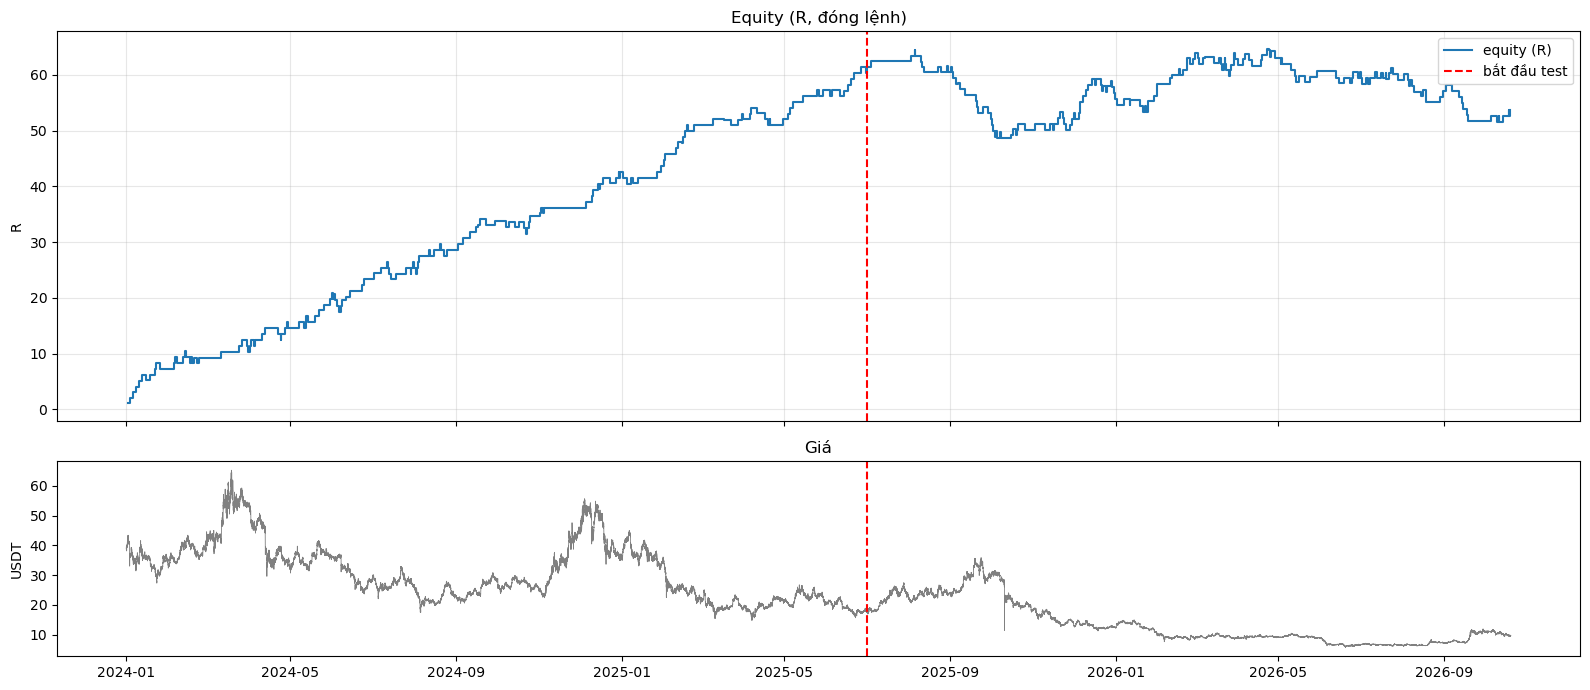

In [110]:
# Backtest một bộ tham số trên toàn bộ dữ liệu. TRIAL_PARAMS (dict) thắng TRIAL_ID; cả hai None = bộ đứng đầu ranked
TRIAL_ID = None
TRIAL_PARAMS = None   # ví dụ {"boll_window": 100, "boll_window_dev": 2.0, "rsi_window": 5, "rsi_threshold": 25,
                      #        "sl_multiplier": 0.9, "tp_sl_ratio": 3.0, "max_holding_bars": 384,
                      #        "vol_window": 96, "vol_days": 30, "vol_ratio_max": 1.0, "trail_r": 0}
if TRIAL_PARAMS is not None:
    params = {**dict(zip(vfe.GRID_COLUMNS, [None] * len(vfe.GRID_COLUMNS))),
              **{k: v[0] for k, v in vfe.OPTIONAL_COLUMNS.items()}, **TRIAL_PARAMS}
    missing = [k for k, v in params.items() if v is None]
    if missing:
        raise ValueError(f"TRIAL_PARAMS thiếu {missing}")
    match = np.all([np.isclose(grid[k].to_numpy(float), float(v)) for k, v in params.items()], axis=0)
    TRIAL_ID = int(np.flatnonzero(match)[0]) if match.any() else None
else:
    if TRIAL_ID is None:
        TRIAL_ID = int(ranked.index[0])
    params = grid.loc[TRIAL_ID].to_dict()
print("Tham số:", params, "| ID trong grid:", TRIAL_ID)
trades = vfe.trace(SIDE, bars, params, TIMEFRAME)
trades = trades[trades.exit_index >= train_from].reset_index(drop=True)
if TRIAL_ID is not None:
    m = months[trades.exit_index.to_numpy()]
    check = np.zeros(R.shape[1])
    np.add.at(check, m[m >= 0], trades.net_r.to_numpy()[m >= 0])
    print(f"Đối chiếu với grid: lệch tối đa theo tháng {np.abs(check - R[TRIAL_ID]).max():.2e}")
trades["phần"] = np.where(trades.exit_index < test_from, "train", "test")
trades["năm"] = pd.to_datetime(trades.exit_timestamp).dt.year
per_year = trades.groupby(["năm", "phần"]).agg(lệnh=("net_r", "size"), R=("net_r", "sum"),
                                              R_mỗi_lệnh=("net_r", "mean"),
                                              tỷ_lệ_thắng=("net_r", lambda s: (s > 0).mean()))
display(per_year.round(3))
display(trades.groupby(["phần", "outcome"]).net_r.agg(["size", "mean", "sum"]).round(3))
eq = trades.set_index(pd.to_datetime(trades.exit_timestamp)).net_r.cumsum()
dd = (np.maximum.accumulate(np.maximum(eq, 0)) - eq)
print(f"Tổng {eq.iloc[-1]:.1f}R trên {len(trades)} lệnh; maxDD theo lệnh {dd.max():.1f}R "
      f"(train {dd[trades.phần.values == 'train'].max():.1f}, test {dd[trades.phần.values == 'test'].max() if (trades.phần == 'test').any() else 0:.1f})")
# vẽ bằng matplotlib trực tiếp: pandas đổi trục của chuỗi giá đều 15min sang Period, làm đường equity (mốc thời gian
# không đều) lệch khỏi khung khi hai biểu đồ dùng chung trục x
price = bars.set_index("timestamp").close.loc[TRAIN_START:]
fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].step(eq.index, eq.to_numpy(), where="post", label="equity (R)")
axes[0].axvline(pd.Timestamp(TEST_START), color="red", ls="--", label="bắt đầu test")
axes[0].set(title="Equity (R, đóng lệnh)", ylabel="R")
axes[0].grid(alpha=0.3)
axes[0].legend()
axes[1].plot(price.index, price.to_numpy(), lw=0.6, color="gray")
axes[1].axvline(pd.Timestamp(TEST_START), color="red", ls="--")
axes[1].set(title="Giá", ylabel="USDT")
plt.tight_layout()
plt.show()

In [109]:
# Nhiều coin (tùy chọn): cùng grid và ngày cho từng coin trong COINS
summary = []
for coin in COINS:
    path = csv_path.parent / f"{coin}usdt_futures_5min.csv"
    try:
        b = vfe.load_bars(path, TIMEFRAME, load_start, TEST_END)
    except (FileNotFoundError, ValueError) as exc:
        print(coin, "bỏ qua:", exc)
        continue
    if b.timestamp.iloc[0] > pd.Timestamp(TRAIN_START) + pd.Timedelta(days=31):
        print(coin, "bỏ qua: dữ liệu bắt đầu", b.timestamp.iloc[0].date())
        continue
    mo = vfe.month_index(b, pd.Timestamp(TRAIN_START).strftime("%Y-%m"))
    tf_ = int(np.searchsorted(b.timestamp.to_numpy(), np.datetime64(pd.Timestamp(TRAIN_START))))
    te_ = int(np.searchsorted(b.timestamp.to_numpy(), np.datetime64(pd.Timestamp(TEST_START))))
    Rc, Nc, st = vfe.run_grid(SIDE, b, grid, TIMEFRAME, mo, stats_from=tf_, stats_to=te_)
    test_r = Rc[:, n_train_m:].sum(1)
    ok = st.number_of_trade >= MIN_TRADES
    row = {"coin": coin}
    for v in sorted(grid.vol_ratio_max.unique()):
        mask = ok & (grid.vol_ratio_max == v)
        if not mask.any():
            continue
        sc = (st.performance / np.maximum(st.max_dd, 1.0)).where(mask)
        top = sc.sort_values(ascending=False).index[:TOP_K]
        row[f"[vol {v:g}] train R/năm trung vị"] = st.performance[mask].median() / train_years
        row[f"[vol {v:g}] test R trung vị"] = np.median(test_r[mask])
        row[f"[vol {v:g}] top-{TOP_K} test R"] = test_r[top].mean()
    summary.append(row)
    print(coin, "xong")
if summary:
    summary = pd.DataFrame(summary).set_index("coin")
    display(summary.round(2))
    display(summary.mean().rename("trung bình").to_frame().T.round(2))